# Stage 4: own solver vs the dataset

Checks whether our pseudo-spectral solver reproduces the dataset's operator $f \mapsto \omega(T)$.

$$\partial_t \omega + u\cdot\nabla\omega = \nu\Delta\omega + f,\qquad u = \nabla^\perp\psi,\quad -\Delta\psi=\omega,\qquad \omega(0)=0,\ T=5$$

Facts used from the paper: $\nu = 1/500$, $\omega(0)=0$, $T=5$, forcing covariance $27(-\Delta+9I)^{-4}$.
Not stated (tested here): axis convention, time step, solver grid.

Settings are chosen on **training** samples; the final agreement is reported on **test** samples that
played no part in any choice. Dataset fields and solver outputs are never mixed in later training.

## Setup

In [1]:
import sys, glob, os, importlib.util
if importlib.util.find_spec("neuralop") is None:
    !pip install -q neuraloperator
# project code (nsbench, optim, solver) comes from the private ns-surrogate-code dataset
code_dir = next((os.path.dirname(os.path.dirname(p)) for p in
                 glob.glob("/kaggle/input/**/nsbench/__init__.py", recursive=True)),
                next(os.path.abspath(d) for d in (".", "..") if os.path.isdir(f"{d}/nsbench")))
sys.path.insert(0, code_dir)
import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nsbench
from nsbench import Trainer, save_csv, save_fig, save_predictions, run_record
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.DataFrame([{"python": sys.version.split()[0], "torch": torch.__version__,
               "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               "code": code_dir}])
from solver import NS2D, timed_solve, rel_l2, forcing_spectrum_model
from nsbench.data import find_data_dir
torch.set_num_threads(os.cpu_count())

/home/jaygupta/projects/FML_Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Raw data (no normalization)

In [2]:
dd = find_data_dir()
train, test = torch.load(f"{dd}/nsforcing_train_128.pt"), torch.load(f"{dd}/nsforcing_test_128.pt")
xtr, ytr = train["x"].double(), train["y"].double()
xte, yte = test["x"].double(), test["y"].double()
pd.DataFrame([{"split": s, "x mean": x.mean().item(), "x std": x.std().item(), "y mean": y.mean().item(),
               "y std": y.std().item()} for s, x, y in (("train", xtr, ytr), ("test", xte, yte))])

,split,x mean,x std,y mean,y std
0,train,1.080188e-10,0.153869,-3.473390e-12,0.707874
1,test,-4.580162e-10,0.153551,-1.056184e-11,0.706248


## Spectrum of the input field

If $x$ is the forcing, its per-mode power should follow $c\,(|k|^2+9)^{-4}$ for some constant $c$
(the constant depends on the KL normalization, which the paper does not give).

[SAVED] results/stage4_input_spectrum.csv


[SAVED] figures/stage4_input_spectrum.png


,fitted c / 27,ratio range k=1..20,ratio range k=21..40
0,17.6717,0.848 to 1.070,1.03 to 1.06


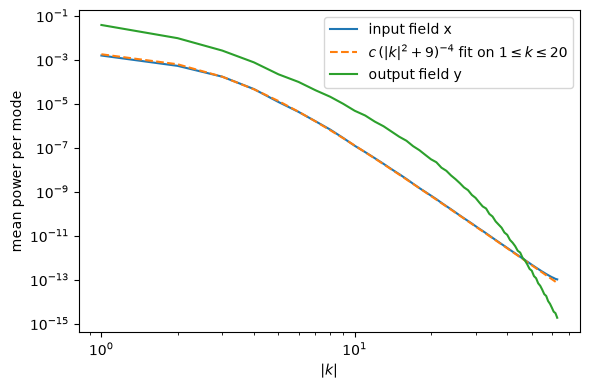

In [3]:
def ring_power(f):
    """Mean |f_hat_k|^2 per mode (norm='forward'), averaged over samples, per ring |k| = round."""
    n = f.shape[-1]
    P = (torch.fft.fft2(f, norm="forward").abs() ** 2).mean(0)
    k1 = torch.fft.fftfreq(n, 1 / n)
    kr = torch.sqrt(k1[:, None] ** 2 + k1[None, :] ** 2).round().long().flatten()
    return (torch.bincount(kr, P.flatten()) / torch.bincount(kr).double())[: n // 2]

px, py = ring_power(xtr[:2000]), ring_power(ytr[:2000])
k = torch.arange(len(px), dtype=torch.float64)
model = forcing_spectrum_model(k) / 27                     # shape only
fit = slice(1, 21)
c = torch.exp((px[fit].log() - model[fit].log()).mean())
ratio = px / (c * model)
spec = pd.DataFrame({"k": k[1:33].long(), "x power": px[1:33], "model c(k^2+9)^-4": (c * model)[1:33],
                     "ratio": ratio[1:33], "y power": py[1:33]})
save_csv(spec, "stage4_input_spectrum")
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(k[1:64], px[1:64], label="input field x")
ax.loglog(k[1:64], (c * model)[1:64], "--", label="$c\\,(|k|^2+9)^{-4}$ fit on $1\\leq k\\leq 20$")
ax.loglog(k[1:64], py[1:64], label="output field y")
ax.set(xlabel="$|k|$", ylabel="mean power per mode"); ax.legend(); fig.tight_layout()
save_fig("stage4_input_spectrum", fig)
pd.DataFrame([{"fitted c / 27": c.item(), "ratio range k=1..20": f"{ratio[fit].min():.3f} to {ratio[fit].max():.3f}",
               "ratio range k=21..40": f"{ratio[21:41].min():.3g} to {ratio[21:41].max():.3g}"}])

## Axis convention and viscosity (8 training samples)

In [4]:
idx = torch.arange(8)
rows = []
for sign in (1.0, -1.0):
    for nu in (1 / 500, 1 / 1000):
        s = NS2D(128, nu=nu, dt=1e-3, method="cn_heun", sign=sign)
        e = rel_l2(s.solve(xtr[idx], T=5.0), ytr[idx])
        rows.append({"sign": sign, "nu": nu, "rel L2 mean": e.mean().item(), "rel L2 max": e.max().item()})
hyp = pd.DataFrame(rows)
save_csv(hyp, "stage4_hypotheses")
SIGN = float(hyp.loc[hyp["rel L2 mean"].idxmin(), "sign"])
NU = float(hyp.loc[hyp["rel L2 mean"].idxmin(), "nu"])
hyp

[SAVED] results/stage4_hypotheses.csv


,sign,nu,rel L2 mean,rel L2 max
0,1.0,0.002,0.000022,0.000035
1,1.0,0.001,0.021545,0.025771
2,-1.0,0.002,0.864222,1.041334
3,-1.0,0.001,0.874651,1.055191


## Time-step and grid convergence (8 training samples)

In [5]:
ref = NS2D(256, nu=NU, dt=1e-3, method="ifrk4", sign=SIGN).solve(xtr[idx], T=5.0, out_res=128)
rows = []
for method, M, dt in [("cn_euler", 128, 2e-3), ("cn_euler", 128, 1e-3), ("cn_heun", 128, 2e-2),
                      ("cn_heun", 128, 1e-2), ("cn_heun", 128, 4e-3), ("cn_heun", 128, 1e-3),
                      ("ifrk4", 128, 2e-3), ("cn_heun", 256, 4e-3)]:
    s = NS2D(M, nu=NU, dt=dt, method=method, sign=SIGN)
    w = s.solve(xtr[idx], T=5.0, out_res=128)
    rows.append({"method": method, "grid": M, "dt": dt,
                 "vs reference (256, ifrk4, dt 1e-3)": rel_l2(w, ref).mean().item(),
                 "vs dataset y": rel_l2(w, ytr[idx]).mean().item()})
rows.append({"method": "ifrk4", "grid": 256, "dt": 1e-3, "vs reference (256, ifrk4, dt 1e-3)": 0.0,
             "vs dataset y": rel_l2(ref, ytr[idx]).mean().item()})
conv = pd.DataFrame(rows)
save_csv(conv, "stage4_convergence")
conv

[SAVED] results/stage4_convergence.csv


,method,grid,dt,"vs reference (256, ifrk4, dt 1e-3)",vs dataset y
0,cn_euler,128,0.002,0.000744,0.000744
1,cn_euler,128,0.001,0.000371,0.000371
2,cn_heun,128,0.020,0.000101,0.000101
3,cn_heun,128,0.010,0.000034,0.000034
4,cn_heun,128,0.004,0.000023,0.000023
5,cn_heun,128,0.001,0.000022,0.000022
6,ifrk4,128,0.002,0.000022,0.000022
7,cn_heun,256,0.004,0.000004,0.000006
8,ifrk4,256,0.001,0.000000,0.000004


## Coarse solves: accuracy vs grid and time step (16 training samples)

A solver run on a coarser grid is cheaper and less accurate. The speedup of a surrogate must be judged
against the cheapest solver setting that reaches the surrogate's accuracy, so this table maps the
trade-off (forcing truncated to the grid, output zero-padded back to $128^2$). Timing is in Stage 5.

In [6]:
idx16 = torch.arange(16)
rows = []
for M in (16, 24, 32, 48, 64, 96, 128):
    for dt in (1e-2, 2e-2, 5e-2, 1e-1):
        w = NS2D(M, nu=NU, dt=dt, method="cn_heun", sign=SIGN).solve(xtr[idx16], T=5.0, out_res=128)
        e = rel_l2(w, ytr[idx16])
        rows.append({"grid": M, "dt": dt, "steps": round(5 / dt), "rel L2 mean": e.mean().item(),
                     "rel L2 max": e.max().item(), "stable": bool(torch.isfinite(e).all() and e.max() < 1)})
coarse = pd.DataFrame(rows)
save_csv(coarse, "stage4_coarse_accuracy")
coarse.pivot(index="grid", columns="dt", values="rel L2 mean")

[SAVED] results/stage4_coarse_accuracy.csv


dt,0.01,0.02,0.05,0.10
grid,,,,
16,0.161001,0.161004,0.161028,0.161132
24,0.078648,0.078652,0.078689,0.078862
32,0.031618,0.031623,0.031664,0.032004
48,0.008857,0.008861,0.008909,0.293769
64,0.002223,0.002227,0.003601,NaN
96,0.000256,0.000275,NaN,NaN
128,0.000032,0.000094,NaN,NaN


## Agreement on held-out test samples

In [7]:
N_TEST = 50
cfg = dict(M=128, nu=NU, dt=1e-3, method="cn_heun", sign=SIGN)
w_te = torch.cat([NS2D(**cfg).solve(xte[i:i + 10], T=5.0) for i in range(0, N_TEST, 10)])
e = rel_l2(w_te, yte[:N_TEST])
agree = pd.DataFrame([{**cfg, "test samples": N_TEST, "rel L2 mean": e.mean().item(), "rel L2 median": e.median().item(),
                       "rel L2 max": e.max().item(), "rel L2 min": e.min().item()}])
save_csv(pd.DataFrame({"sample": range(N_TEST), "rel_L2": e.numpy()}), "stage4_test_per_sample")
save_csv(agree, "stage4_test_agreement")
agree

[SAVED] results/stage4_test_per_sample.csv
[SAVED] results/stage4_test_agreement.csv


,M,nu,dt,method,sign,test samples,rel L2 mean,rel L2 median,rel L2 max,rel L2 min
0,128,0.002,0.001,cn_heun,1.0,50,0.000027,0.000017,0.000205,0.000013


## Example fields

[SAVED] figures/stage4_examples.png


PosixPath('figures/stage4_examples.png')

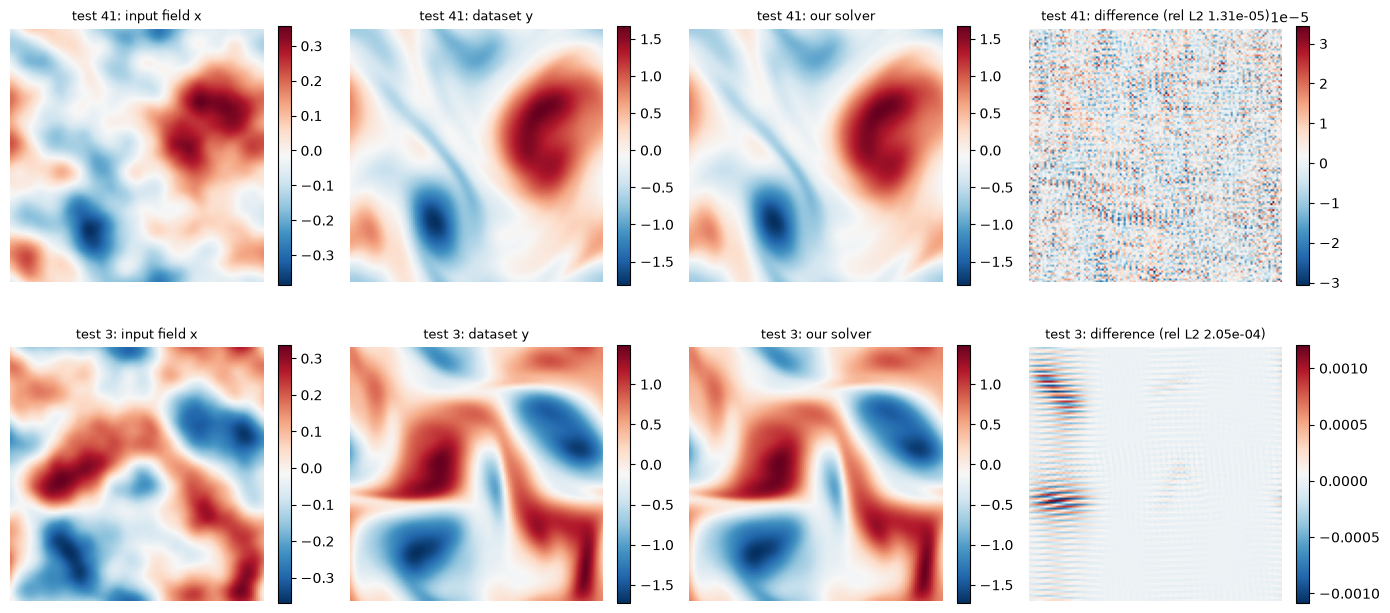

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(14, 6.5))
for r, i in enumerate((int(e.argmin()), int(e.argmax()))):
    for c_, (img, t) in enumerate([(xte[i], "input field x"), (yte[i], "dataset y"), (w_te[i], "our solver"),
                                   (w_te[i] - yte[i], f"difference (rel L2 {e[i]:.2e})")]):
        im = ax[r, c_].imshow(img, cmap="RdBu_r"); ax[r, c_].set_title(f"test {i}: {t}", fontsize=9)
        ax[r, c_].axis("off"); fig.colorbar(im, ax=ax[r, c_], fraction=0.046)
fig.tight_layout()
save_fig("stage4_examples", fig)